# Klasifikasi Tingkat Produksi Padi di Pulau Sumatera
**Perbandingan SVM, Naive Bayes, KNN, dan Decision Tree dengan 5-Fold Cross-Validation**

Kelompok: *(isi nama anggota + NIM)*  
Dataset: `Data_Tanaman_Padi_Sumatera_version_1.csv` (8 provinsi, 1993-2020, 224 baris)

## 1. Import Library

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import os; os.makedirs('figures', exist_ok=True)
RS = 42
sns.set_style('whitegrid')

## 2. Load Data & Eksplorasi Awal

In [2]:
df = pd.read_csv('Data_Tanaman_Padi_Sumatera_version_1.csv', encoding='utf-8-sig')
print(df.shape)
df.head()

(224, 7)


,Provinsi,Tahun,Produksi,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
0,Aceh,1993,1329536.0,323589.0,1627.0,82.00,26.06
1,Aceh,1994,1299699.0,329041.0,1521.0,82.12,26.92
2,Aceh,1995,1382905.0,339253.0,1476.0,82.72,26.27
3,Aceh,1996,1419128.0,348223.0,1557.0,83.00,26.08
4,Aceh,1997,1368074.0,337561.0,1339.0,82.46,26.31


In [3]:
print(df.info())
print('Missing value  :', df.isna().sum().sum())
print('Duplikat       :', df.duplicated().sum())
print('Jumlah/provinsi:'); print(df['Provinsi'].value_counts())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 224 entries, 0 to 223
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Provinsi        224 non-null    str    
 1   Tahun           224 non-null    int64  
 2   Produksi        224 non-null    float64
 3   Luas Panen      224 non-null    float64
 4   Curah hujan     224 non-null    float64
 5   Kelembapan      224 non-null    float64
 6   Suhu rata-rata  224 non-null    float64
dtypes: float64(5), int64(1), str(1)
memory usage: 12.4 KB
None
Missing value  : 0
Duplikat       : 0
Jumlah/provinsi:
Provinsi
Aceh                28
Sumatera Utara      28
Sumatera Barat      28
Riau                28
Jambi               28
Sumatera Selatan    28
Bengkulu            28
Lampung             28
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Tahun,224.0,2.006500e+03,8.095838e+00,1993.00,1999.7500,2006.500,2013.25,2020.00
Produksi,224.0,1.679701e+06,1.161387e+06,42938.00,548857.0000,1667773.000,2436850.75,4881089.00
Luas Panen,224.0,3.743500e+05,2.327512e+05,63142.04,146919.5000,373551.500,514570.25,872737.00
Curah hujan,224.0,2.452491e+03,1.031973e+03,222.50,1703.5250,2315.700,3039.70,5522.00
Kelembapan,224.0,8.094871e+01,4.878680e+00,54.20,78.9750,82.375,84.00,90.60
Suhu rata-rata,224.0,2.680196e+01,1.197041e+00,22.19,26.1775,26.730,27.20,29.85


### 2.1 Distribusi & Korelasi

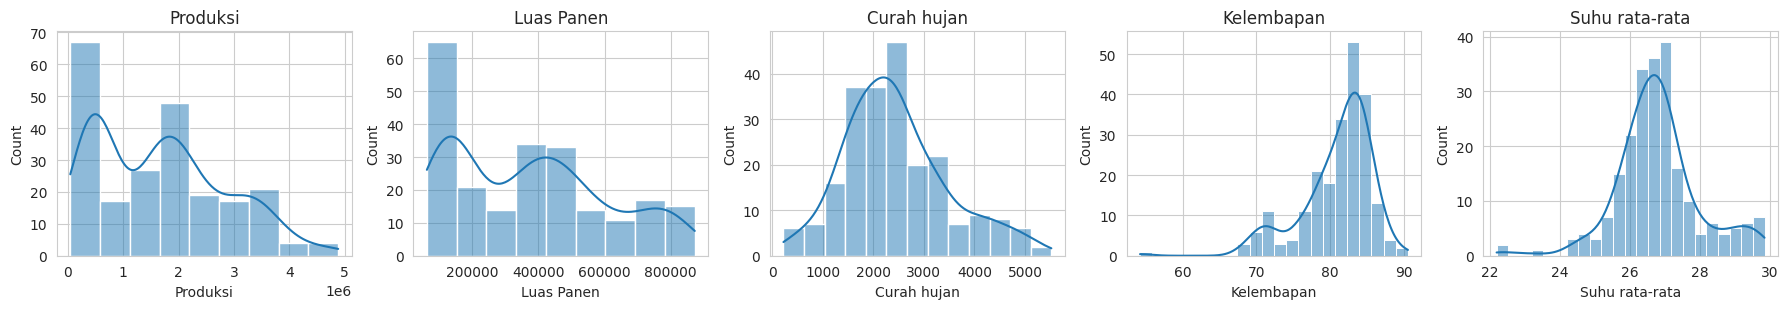

In [4]:
num = ['Produksi','Luas Panen','Curah hujan','Kelembapan','Suhu rata-rata']
fig, ax = plt.subplots(1, 5, figsize=(18, 3.2))
for a, c in zip(ax, num):
    sns.histplot(df[c], kde=True, ax=a); a.set_title(c)
plt.tight_layout(); plt.savefig('figures/fig_distribusi.png', dpi=200); plt.show()

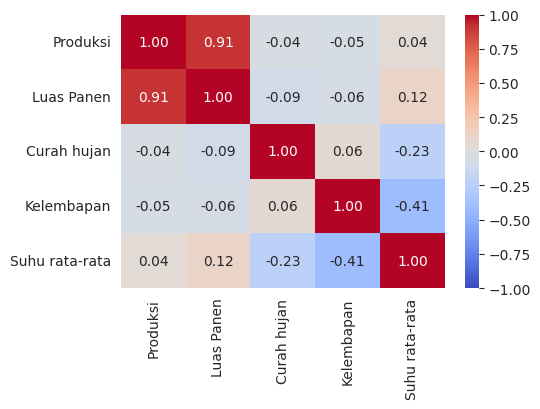

In [5]:
plt.figure(figsize=(5.5, 4.2))
sns.heatmap(df[num].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.tight_layout(); plt.savefig('figures/fig_korelasi.png', dpi=200); plt.show()

**Catatan:** `Luas Panen` berkorelasi sangat kuat dengan `Produksi` (r ≈ 0,91), sedangkan variabel iklim (curah hujan, kelembapan, suhu) hampir tidak berkorelasi langsung dengan produksi.

## 3. Preprocessing
Semua algoritma yang dipakai adalah **klasifikasi**, sedangkan `Produksi` bertipe numerik. Maka `Produksi` didiskretisasi menjadi 3 kelas **berdasarkan tertil (qcut)**: *Rendah, Sedang, Tinggi*, sehingga kelas relatif seimbang.

Kelas
Rendah    75
Tinggi    75
Sedang    74
Name: count, dtype: int64
              min        max
Kelas                       
Rendah    42938.0   628828.0
Sedang   629224.0  1977345.0
Tinggi  1992726.0  4881089.0


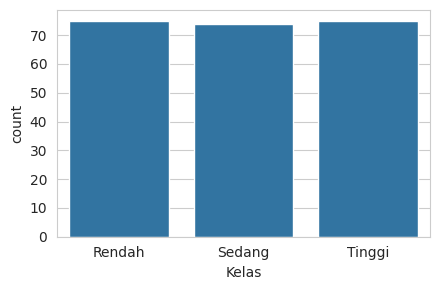

In [6]:
df['Kelas'] = pd.qcut(df['Produksi'], 3, labels=['Rendah','Sedang','Tinggi'])
print(df['Kelas'].value_counts())
print(df.groupby('Kelas')['Produksi'].agg(['min','max']))
plt.figure(figsize=(4.5,3)); sns.countplot(x='Kelas', data=df, order=['Rendah','Sedang','Tinggi'])
plt.tight_layout(); plt.savefig('figures/fig_kelas.png', dpi=200); plt.show()

Dua skenario fitur dibandingkan:
- **Skenario A** (lengkap): Luas Panen + Curah hujan + Kelembapan + Suhu
- **Skenario B** (iklim saja): Curah hujan + Kelembapan + Suhu (tanpa Luas Panen)

`Provinsi` dan `Tahun` **tidak** dipakai sebagai fitur agar model benar-benar belajar dari faktor lahan & iklim.

In [7]:
y = df['Kelas']
SKENARIO = {
    'A (dengan Luas Panen)': ['Luas Panen','Curah hujan','Kelembapan','Suhu rata-rata'],
    'B (iklim saja)':        ['Curah hujan','Kelembapan','Suhu rata-rata'],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
models = {
    'SVM': make_pipeline(StandardScaler(), SVC(random_state=RS)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier()),
    'Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(random_state=RS),
}

## 4. Baseline: 5-Fold Cross-Validation (parameter default)
`StandardScaler` dimasukkan ke dalam `Pipeline` sehingga scaling hanya di-fit pada data latih tiap fold (mencegah data leakage).

In [8]:
scoring = ['accuracy','precision_macro','recall_macro','f1_macro']
rows, fold_acc = [], {}
for sk, feats in SKENARIO.items():
    X = df[feats]
    for name, m in models.items():
        s = cross_validate(m, X, y, cv=cv, scoring=scoring)
        fold_acc[(sk, name)] = s['test_accuracy']
        rows.append({'Skenario': sk, 'Model': name,
                     'Akurasi': s['test_accuracy'].mean(), 'Std': s['test_accuracy'].std(),
                     'Presisi': s['test_precision_macro'].mean(),
                     'Recall': s['test_recall_macro'].mean(),
                     'F1-macro': s['test_f1_macro'].mean()})
base = pd.DataFrame(rows)
base.round(3)

,Skenario,Model,Akurasi,Std,Presisi,Recall,F1-macro
0,A (dengan Luas Panen),SVM,0.812,0.042,0.817,0.812,0.809
1,A (dengan Luas Panen),KNN,0.781,0.041,0.788,0.781,0.778
2,A (dengan Luas Panen),Naive Bayes,0.817,0.045,0.820,0.816,0.812
3,A (dengan Luas Panen),Decision Tree,0.808,0.047,0.812,0.807,0.807
4,B (iklim saja),SVM,0.464,0.052,0.476,0.463,0.458
5,B (iklim saja),KNN,0.451,0.053,0.455,0.450,0.436
6,B (iklim saja),Naive Bayes,0.406,0.065,0.405,0.405,0.388
7,B (iklim saja),Decision Tree,0.455,0.047,0.457,0.455,0.453


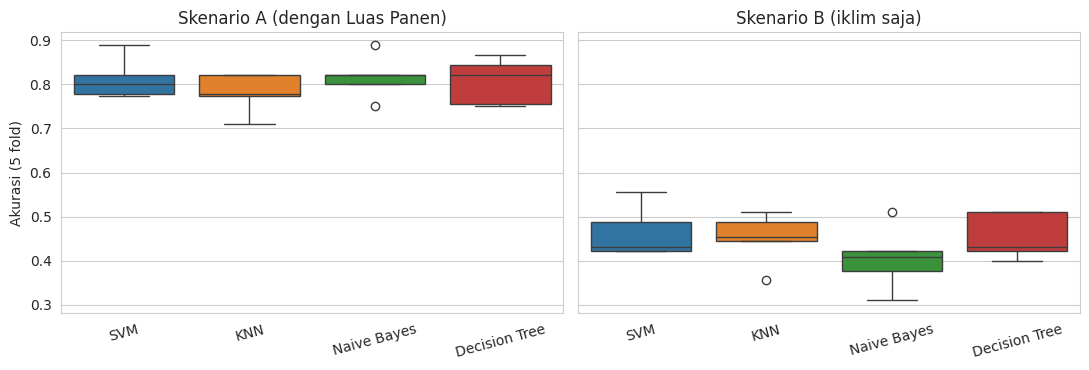

In [9]:
base.round(3).to_csv('hasil_baseline.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, sk in zip(ax, SKENARIO):
    data = pd.DataFrame({n: fold_acc[(sk, n)] for n in models})
    sns.boxplot(data=data, ax=a); a.set_title('Skenario ' + sk); a.set_ylabel('Akurasi (5 fold)')
    a.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.savefig('figures/fig_boxplot_cv.png', dpi=200); plt.show()

## 5. Hyperparameter Tuning (Nested Cross-Validation)
Tuning memakai `GridSearchCV` (inner 3-fold) di dalam outer 5-fold sehingga estimasi performa tetap tidak bias.

In [10]:
grids = {
    'SVM': (models['SVM'], {'svc__C':[0.1,1,10,100], 'svc__gamma':['scale',0.1,0.01], 'svc__kernel':['rbf','linear']}),
    'KNN': (models['KNN'], {'kneighborsclassifier__n_neighbors':[3,5,7,9,11], 'kneighborsclassifier__weights':['uniform','distance']}),
    'Naive Bayes': (models['Naive Bayes'], {'var_smoothing':[1e-9,1e-8,1e-7,1e-5,1e-3]}),
    'Decision Tree': (models['Decision Tree'], {'max_depth':[2,3,4,5,7,None], 'min_samples_leaf':[1,3,5,10], 'criterion':['gini','entropy']}),
}
inner = StratifiedKFold(3, shuffle=True, random_state=RS)
rows = []
for sk, feats in SKENARIO.items():
    X = df[feats]
    for name, (m, g) in grids.items():
        gs = GridSearchCV(m, g, cv=inner, scoring='f1_macro')
        s = cross_validate(gs, X, y, cv=cv, scoring=['accuracy','f1_macro'])
        rows.append({'Skenario': sk, 'Model': name,
                     'Akurasi': s['test_accuracy'].mean(), 'Std': s['test_accuracy'].std(),
                     'F1-macro': s['test_f1_macro'].mean()})
tuned = pd.DataFrame(rows)
tuned.round(3)

,Skenario,Model,Akurasi,Std,F1-macro
0,A (dengan Luas Panen),SVM,0.812,0.031,0.807
1,A (dengan Luas Panen),KNN,0.808,0.047,0.805
2,A (dengan Luas Panen),Naive Bayes,0.821,0.046,0.816
3,A (dengan Luas Panen),Decision Tree,0.803,0.061,0.800
4,B (iklim saja),SVM,0.464,0.076,0.454
5,B (iklim saja),KNN,0.455,0.046,0.449
6,B (iklim saja),Naive Bayes,0.393,0.076,0.377
7,B (iklim saja),Decision Tree,0.464,0.053,0.453


In [11]:
tuned.round(3).to_csv('hasil_tuned.csv', index=False)
cmp = base[['Skenario','Model','Akurasi','F1-macro']].merge(tuned[['Skenario','Model','Akurasi','F1-macro']],
        on=['Skenario','Model'], suffixes=(' (default)',' (tuned)'))
cmp.round(3)

,Skenario,Model,Akurasi (default),F1-macro (default),Akurasi (tuned),F1-macro (tuned)
0,A (dengan Luas Panen),SVM,0.812,0.809,0.812,0.807
1,A (dengan Luas Panen),KNN,0.781,0.778,0.808,0.805
2,A (dengan Luas Panen),Naive Bayes,0.817,0.812,0.821,0.816
3,A (dengan Luas Panen),Decision Tree,0.808,0.807,0.803,0.800
4,B (iklim saja),SVM,0.464,0.458,0.464,0.454
5,B (iklim saja),KNN,0.451,0.436,0.455,0.449
6,B (iklim saja),Naive Bayes,0.406,0.388,0.393,0.377
7,B (iklim saja),Decision Tree,0.455,0.453,0.464,0.453


## 6. Analisis Lanjutan (Skenario A)
### 6.1 Confusion Matrix

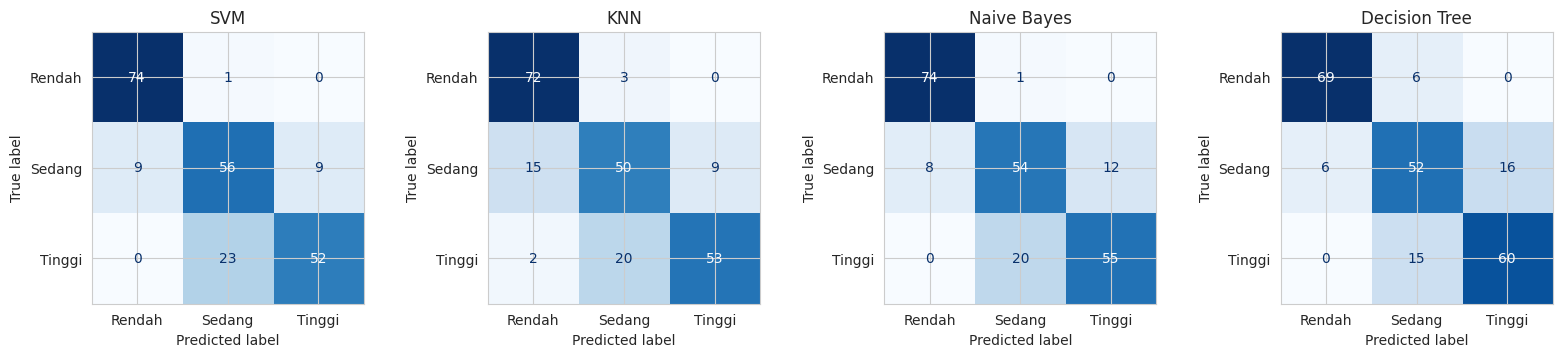

In [12]:
XA = df[SKENARIO['A (dengan Luas Panen)']]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, (name, m) in zip(ax, models.items()):
    pred = cross_val_predict(m, XA, y, cv=cv)
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=['Rendah','Sedang','Tinggi']),
                           display_labels=['Rendah','Sedang','Tinggi']).plot(ax=a, colorbar=False, cmap='Blues')
    a.set_title(name)
plt.tight_layout(); plt.savefig('figures/fig_confusion.png', dpi=200); plt.show()

### 6.2 Pentingnya Fitur (Decision Tree & Permutation Importance)

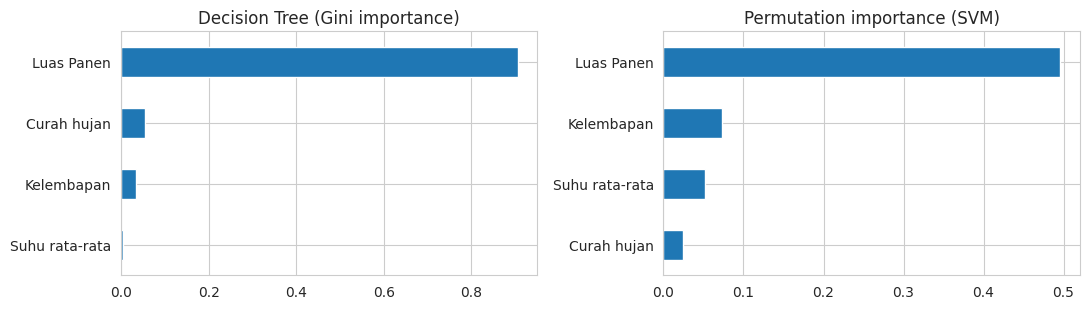

{'Suhu rata-rata': 0.005, 'Kelembapan': 0.034, 'Curah hujan': 0.055, 'Luas Panen': 0.906}


In [13]:
dt = DecisionTreeClassifier(random_state=RS, max_depth=4).fit(XA, y)
imp = pd.Series(dt.feature_importances_, index=XA.columns).sort_values()
perm = permutation_importance(models['SVM'].fit(XA, y), XA, y, n_repeats=20, random_state=RS)
perm = pd.Series(perm.importances_mean, index=XA.columns).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
imp.plot.barh(ax=ax[0], title='Decision Tree (Gini importance)')
perm.plot.barh(ax=ax[1], title='Permutation importance (SVM)')
plt.tight_layout(); plt.savefig('figures/fig_importance.png', dpi=200); plt.show()
print(imp.round(3).to_dict())

### 6.3 Uji Ketahanan: Leave-Province-Out (GroupKFold)
Data antar-tahun dalam satu provinsi saling mirip, sehingga CV acak bisa terlalu optimis. Di sini seluruh data satu provinsi ditahan sebagai data uji (tanpa muncul di data latih).

In [14]:
gkf = GroupKFold(n_splits=4)
rows = []
for sk, feats in SKENARIO.items():
    for name, m in models.items():
        s = cross_validate(m, df[feats], y, cv=gkf, groups=df['Provinsi'], scoring=['accuracy','f1_macro'])
        rows.append({'Skenario': sk, 'Model': name, 'Akurasi': s['test_accuracy'].mean(), 'F1-macro': s['test_f1_macro'].mean()})
group_res = pd.DataFrame(rows); group_res.to_csv('hasil_groupkfold.csv', index=False)
group_res.round(3)

,Skenario,Model,Akurasi,F1-macro
0,A (dengan Luas Panen),SVM,0.710,0.591
1,A (dengan Luas Panen),KNN,0.688,0.537
2,A (dengan Luas Panen),Naive Bayes,0.768,0.653
3,A (dengan Luas Panen),Decision Tree,0.701,0.599
4,B (iklim saja),SVM,0.241,0.221
5,B (iklim saja),KNN,0.246,0.221
6,B (iklim saja),Naive Bayes,0.179,0.153
7,B (iklim saja),Decision Tree,0.299,0.254


### 6.4 Metrik per Kelas (Skenario A)

In [15]:
from sklearn.metrics import classification_report
rows = []
for name, m in models.items():
    pred = cross_val_predict(m, XA, y, cv=cv)
    rep = classification_report(y, pred, output_dict=True)
    for k in ['Rendah','Sedang','Tinggi']:
        rows.append({'Model': name, 'Kelas': k, 'Presisi': rep[k]['precision'], 'Recall': rep[k]['recall'], 'F1': rep[k]['f1-score']})
perclass = pd.DataFrame(rows); perclass.to_csv('hasil_perkelas.csv', index=False)
perclass.round(3)

,Model,Kelas,Presisi,Recall,F1
0,SVM,Rendah,0.892,0.987,0.937
1,SVM,Sedang,0.700,0.757,0.727
2,SVM,Tinggi,0.852,0.693,0.765
3,KNN,Rendah,0.809,0.960,0.878
4,KNN,Sedang,0.685,0.676,0.680
5,KNN,Tinggi,0.855,0.707,0.774
6,Naive Bayes,Rendah,0.902,0.987,0.943
7,Naive Bayes,Sedang,0.720,0.730,0.725
8,Naive Bayes,Tinggi,0.821,0.733,0.775
9,Decision Tree,Rendah,0.920,0.920,0.920


### 6.5 Repeated Stratified 5-Fold (5 pengulangan)
Untuk menstabilkan estimasi karena data kecil, CV 5-fold diulang 5 kali dengan pengacakan berbeda (total 25 lipatan).

In [16]:
from sklearn.model_selection import RepeatedStratifiedKFold
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RS)
rows = []
for sk, feats in SKENARIO.items():
    for name, m in models.items():
        s = cross_validate(m, df[feats], y, cv=rcv, scoring=['accuracy','f1_macro'])
        rows.append({'Skenario': sk, 'Model': name, 'Akurasi': s['test_accuracy'].mean(), 'Std': s['test_accuracy'].std(), 'F1-macro': s['test_f1_macro'].mean()})
rep_res = pd.DataFrame(rows); rep_res.to_csv('hasil_repeated.csv', index=False)
rep_res.round(3)

,Skenario,Model,Akurasi,Std,F1-macro
0,A (dengan Luas Panen),SVM,0.804,0.049,0.800
1,A (dengan Luas Panen),KNN,0.767,0.055,0.762
2,A (dengan Luas Panen),Naive Bayes,0.818,0.039,0.815
3,A (dengan Luas Panen),Decision Tree,0.812,0.050,0.811
4,B (iklim saja),SVM,0.448,0.066,0.441
5,B (iklim saja),KNN,0.450,0.056,0.442
6,B (iklim saja),Naive Bayes,0.378,0.052,0.355
7,B (iklim saja),Decision Tree,0.434,0.068,0.429


### 6.6 Hyperparameter Terbaik (GridSearchCV pada seluruh data Skenario A)

In [17]:
for name, (m, g) in grids.items():
    gs = GridSearchCV(m, g, cv=cv, scoring='f1_macro').fit(XA, y)
    print(f"{name:14s} best F1={gs.best_score_:.3f}  params={gs.best_params_}")

SVM            best F1=0.830  params={'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}


KNN            best F1=0.798  params={'kneighborsclassifier__n_neighbors': 11, 'kneighborsclassifier__weights': 'distance'}
Naive Bayes    best F1=0.821  params={'var_smoothing': 0.001}


Decision Tree  best F1=0.860  params={'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1}


### 6.7 Sebaran Kelas per Provinsi

In [18]:
ct = pd.crosstab(df['Provinsi'], df['Kelas']); ct.to_csv('hasil_crosstab.csv'); ct

Kelas,Rendah,Sedang,Tinggi
Provinsi,,,
Aceh,0,25,3
Bengkulu,26,2,0
Jambi,21,7,0
Lampung,0,10,18
Riau,28,0,0
Sumatera Barat,0,19,9
Sumatera Selatan,0,11,17
Sumatera Utara,0,0,28


## 7. Kesimpulan
- Pada **Skenario A**, keempat model mencapai akurasi sekitar 78-82%, selisih antar model kecil, dengan `Luas Panen` sebagai prediktor dominan.
- Pada **Skenario B** (tanpa `Luas Panen`), akurasi turun drastis (~40-46%, hanya sedikit di atas tebakan acak 33%), artinya variabel iklim saja belum cukup menjelaskan tingkat produksi.
- Uji leave-province-out menunjukkan CV acak cenderung optimis karena kemiripan data antar-tahun dalam satu provinsi.
- Tuning hyperparameter memberi peningkatan kecil (paling terlihat pada KNN, sekitar 78% menjadi 81%); pemilihan fitur lebih berpengaruh daripada pemilihan algoritma.

> **Etika & keterbatasan:** data bersifat agregat tingkat provinsi (tidak memuat data pribadi); hasil tidak boleh dipakai langsung sebagai dasar kebijakan karena jumlah data kecil, kelas dibuat dari tertil (bukan standar resmi), dan faktor lain (irigasi, pupuk, jenis lahan) tidak ada di dataset.